In [2]:
import math
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import linear_sum_assignment

In [3]:
SEED = 42
DEVICE = 'mps'

batch_size = 128
lr_phase1 = 1e-3
lr_phase2 = 1e-4
output_scale = 100.0

tau_star = 1.0
tau_s = 2.0
dt = 0.025
eps_max = 0.1

emm_phase1_steps = 2_500

emm_phase2_steps = 500
cd_weight = 1e-3
neg_langevin_steps = 75
trim_alpha = 0.1
clamp_beta = 0.05

torch.manual_seed(SEED)
np.random.seed(SEED)

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [5]:
def sample_noise(batch_size):
    return torch.randn(batch_size, 1, 28, 28)

train_iter = iter(train_loader)
def sample_data(batch_size):
    global train_iter
    try:
        return next(train_iter)[0]
    except StopIteration:
        train_iter = iter(train_loader)
        return next(train_iter)[0]

In [6]:
def plot_losses(losses, color = 'tab:blue', ws = 100, ax = None, label = "Loss"):
    if ax is None:
        fig, ax = plt.subplots()

    losses = np.asarray(losses)
    ws = min(ws, len(losses))
    ax.plot(losses, label=label, color=color, alpha=0.5)
    smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
    ax.plot(np.arange(ws-1, len(losses)), smoothed, label=f"Smoothed {label}", color=color)

    ax.legend()
    ax.grid()

def plot_samples(x, n_cols=8, figsize_scale=1.2):
    x = x.detach().cpu().squeeze(1)  
    n = x.shape[0]
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_scale, n_rows * figsize_scale))
    axes = axes.flatten() if n > 1 else [axes]

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(x[i], cmap="gray", vmin=-1, vmax=1)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [7]:
class EnergyMatchingCNN(nn.Module):
    def __init__(self, in_ch=1, base_ch=32, hidden_dim=256, output_scale=100.0):
        super().__init__()

        self.output_scale = output_scale

        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, base_ch, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch, base_ch, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch, base_ch * 2, 4, stride=2, padding=1),        # 28 -> 14
            nn.SiLU(),
            nn.Conv2d(base_ch * 2, base_ch * 2, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(base_ch * 2, base_ch * 4, 4, stride=2, padding=1),    # 14 -> 7
            nn.SiLU(),
            nn.Conv2d(base_ch * 4, base_ch * 4, 3, padding=1),
            nn.SiLU(),
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(base_ch * 4 * 7 * 7, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.head(self.conv(x)).squeeze(-1) * self.output_scale  # shape: (B,)

In [8]:
def ot_couple(x0, x1):
    cost = torch.cdist(x0.flatten(1), x1.flatten(1)) ** 2
    row_ind, col_ind = linear_sum_assignment(cost.cpu().detach().numpy())

    return x0[row_ind], x1[col_ind]

def grad_V(V, x, create_graph=True):
    x = x.detach().requires_grad_(True)
    energy = V(x)
    grad = torch.autograd.grad(energy.sum(), x, create_graph=create_graph)[0]
    return grad

def phase1_loss(V, x_0, x_1, t):
    x_0, x_1 = ot_couple(x_0, x_1)
    x_t = (1 - t) * x_0 + t * x_1
    target = x_0 - x_1

    pred = grad_V(V, x_t)

    return ((pred - target) ** 2).sum(dim=(1, 2, 3)).mean()

def eps_schedule(t, eps_max, tau_star):
    if t < tau_star:
        return 0.0
    if tau_star < 1.0 and t < 1.0:
        return eps_max * (t - tau_star) / (1.0 - tau_star)
    return eps_max

def langevin(V, x, n_steps, dt, eps_fn):
    x = x.clone().detach()
    for m in range(n_steps):
        g = grad_V(V, x, create_graph=False).detach()
        eps = eps_fn(m)
        x = x - dt * g + math.sqrt(2 * dt * eps) * torch.randn_like(x)

    return x.detach()

def ode_integrate(V, x, tau=1.0, dt=0.025):
    return langevin(V, x, int(round(tau / dt)), dt, lambda m: 0.0)

def sample_emm(V, x_0, tau_s=2.0, dt=0.025, eps_max=0.1, tau_star=1.0):
    return langevin(V, x_0, int(round(tau_s / dt)), dt, lambda m: eps_schedule(m * dt, eps_max, tau_star))

def trimmed_mean(v, alpha):
    k = int(alpha * v.numel())
    if k == 0:
        return v.mean()
    return torch.sort(v)[0][:v.numel() - k].mean()

def phase2_loss(V, x_0, x_1, t, dt, eps_max, tau_star, cd_weight, n_langevin_steps, trim_alpha, clamp_beta):
    ot_loss = phase1_loss(V, x_0, x_1, t)

    half = x_1.shape[0] // 2
    x_neg_data = langevin(V, x_1[:half], n_langevin_steps, dt, lambda m: eps_max)
    x_neg_noise = langevin(V, x_0[half:], n_langevin_steps, dt, lambda m: eps_schedule(m * dt, eps_max, tau_star))
    x_neg = torch.cat([x_neg_data, x_neg_noise], dim=0)

    v_data = V(x_1)
    v_neg = V(x_neg)

    cd_loss = (v_data.mean() - trimmed_mean(v_neg, trim_alpha)) / eps_max
    cd_loss = torch.clamp(cd_loss, min=-clamp_beta)

    return ot_loss + cd_weight * cd_loss, ot_loss.detach(), cd_loss.detach()

In [9]:
emm = EnergyMatchingCNN(output_scale=output_scale).to(DEVICE)
optimizer = torch.optim.Adam(emm.parameters(), lr_phase1)

In [10]:
x_0 = sample_noise(batch_size).to(DEVICE)
x_1 = sample_data(batch_size).to(DEVICE)
x_0c, x_1c = ot_couple(x_0, x_1)

with torch.no_grad():
    v = emm(x_1)
g = grad_V(emm, x_1, create_graph=False)
print(f"V(data) at init:      {v.mean():.3f} +- {v.std():.3f}")
print(f"|grad V(data)| at init: {g.flatten(1).norm(dim=1).mean():.3f}")
print(f"|x_0 - x_1| (OT pairs): {(x_0c - x_1c).flatten(1).norm(dim=1).mean():.3f}")
print(f"phase 1 loss for grad V = 0: {((x_0c - x_1c) ** 2).sum(dim=(1, 2, 3)).mean():.1f}")

V(data) at init:      -1.906 +- 0.008
|grad V(data)| at init: 0.009
|x_0 - x_1| (OT pairs): 37.806
phase 1 loss for grad V = 0: 1430.0


100%|██████████| 2500/2500 [02:45<00:00, 15.09it/s, Loss=185.64]


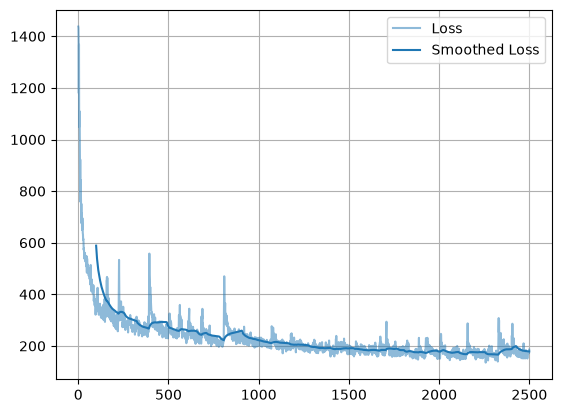

In [11]:
emm.train()
phase1_losses = []
with tqdm(range(emm_phase1_steps)) as pb:
    for i in pb:
        x_0 = sample_noise(batch_size).to(DEVICE)
        x_1 = sample_data(batch_size).to(DEVICE)
        t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE) * tau_star

        optimizer.zero_grad()
        loss = phase1_loss(emm, x_0, x_1, t)
        loss.backward()
        optimizer.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}'})
        phase1_losses.append(loss.item())

plot_losses(phase1_losses, color='tab:blue')
plt.show()

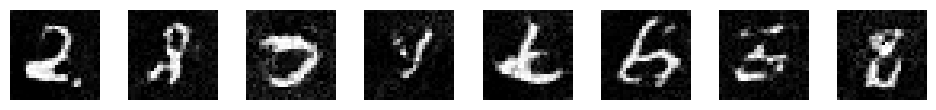

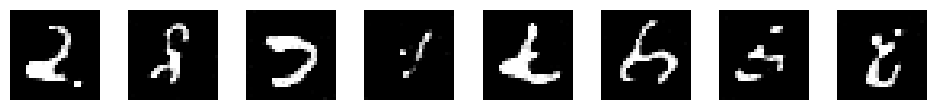

In [12]:
emm.eval()
x_0 = sample_noise(8).to(DEVICE)

samples = ode_integrate(emm, x_0, tau=tau_star, dt=dt)
plot_samples(samples)

samples = sample_emm(emm, x_0, tau_s=tau_s, dt=dt, eps_max=eps_max, tau_star=tau_star)
plot_samples(samples)

100%|██████████| 500/500 [07:36<00:00,  1.09it/s, Loss=161.64, OT=161.19, CD=445.709]


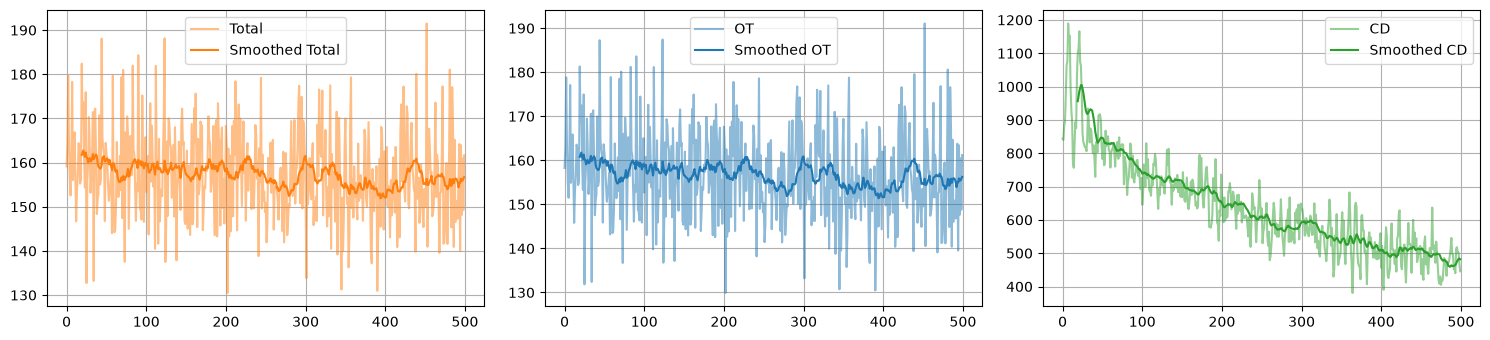

In [13]:
emm.train()
for group in optimizer.param_groups:
    group['lr'] = lr_phase2

phase2_losses, phase2_ot_losses, phase2_cd_losses = [], [], []
with tqdm(range(emm_phase2_steps)) as pb:
    for i in pb:
        x_0 = sample_noise(batch_size).to(DEVICE)
        x_1 = sample_data(batch_size).to(DEVICE)
        t = torch.rand(x_0.shape[0], 1, 1, 1, device=DEVICE) * tau_star

        optimizer.zero_grad()
        loss, ot_loss, cd_loss = phase2_loss(
            emm, x_0, x_1, t, dt, eps_max, tau_star, cd_weight, neg_langevin_steps, trim_alpha, clamp_beta
        )
        loss.backward()
        optimizer.step() 

        pb.set_postfix({'Loss': f'{loss.item():.2f}', 'OT': f'{ot_loss.item():.2f}', 'CD': f'{cd_loss.item():.3f}'})
        phase2_losses.append(loss.item())
        phase2_ot_losses.append(ot_loss.item())
        phase2_cd_losses.append(cd_loss.item())

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
plot_losses(phase2_losses, color='tab:orange', ws=20, ax=axs[0], label="Total")
plot_losses(phase2_ot_losses, color='tab:blue', ws=20, ax=axs[1], label="OT")
plot_losses(phase2_cd_losses, color='tab:green', ws=20, ax=axs[2], label="CD")
fig.tight_layout()
plt.show()

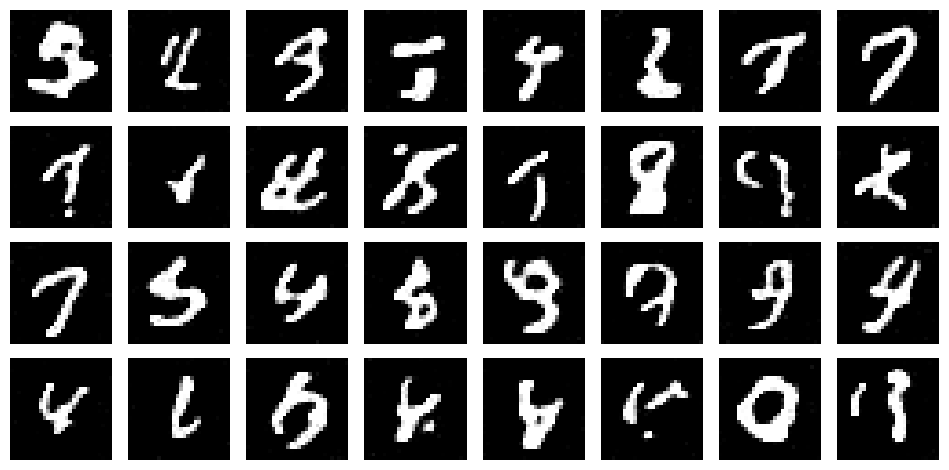

In [14]:
emm.eval()
x_0 = sample_noise(32).to(DEVICE)

samples = sample_emm(emm, x_0, tau_s=tau_s, dt=dt, eps_max=eps_max, tau_star=tau_star).cpu()
plot_samples(samples)

V(data):    359.9 +- 37.8
V(samples): 317.7 +- 29.8
V(noise):   1647.2 +- 32.8


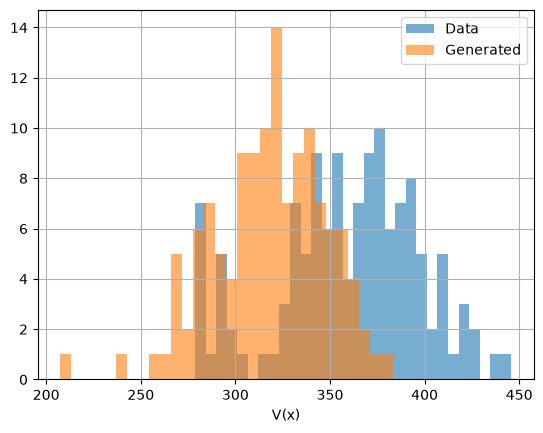

In [20]:
# Energy of data vs. generated samples vs. noise: after phase 2 data and samples should have similar (low) energy
emm.eval()
x_1 = sample_data(batch_size).to(DEVICE)
x_0 = sample_noise(batch_size).to(DEVICE)
x_gen = sample_emm(emm, x_0, tau_s=tau_s, dt=dt, eps_max=eps_max, tau_star=tau_star)

with torch.no_grad():
    v_data, v_gen, v_noise = emm(x_1).cpu(), emm(x_gen).cpu(), emm(x_0).cpu()

print(f"V(data):    {v_data.mean():.1f} +- {v_data.std():.1f}")
print(f"V(samples): {v_gen.mean():.1f} +- {v_gen.std():.1f}")
print(f"V(noise):   {v_noise.mean():.1f} +- {v_noise.std():.1f}")

fig, ax = plt.subplots()
ax.hist(v_data.numpy(), bins=30, alpha=0.6, label="Data")
ax.hist(v_gen.numpy(), bins=30, alpha=0.6, label="Generated")
# ax.hist(v_noise.numpy(), bins=30, alpha=0.6, label="Noise")
ax.set_xlabel("V(x)")
ax.legend()
ax.grid()
plt.show()

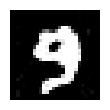

tensor([377.3740], grad_fn=<ToCopyBackward0>)

In [81]:
tau_star = 1.0
tau_s = 2.0
dt = 0.1
eps_max = 0.05

x_0 = sample_noise(1).to(DEVICE)
x_gen = sample_emm(emm, x_0, tau_s=tau_s, dt=dt, eps_max=eps_max, tau_star=tau_star)


plot_samples(x_gen)
emm(x_gen).cpu()